In [19]:
import Pkg; Pkg.add("LambertW")

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.11/Project.toml`
  No Changes to `~/.julia/environments/v1.11/Manifest.toml`


In [20]:
import Pkg; Pkg.add("QuadGK")

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.11/Project.toml`
  No Changes to `~/.julia/environments/v1.11/Manifest.toml`


### 0. Defining constants and functions

In [21]:
using LinearAlgebra
using Plots
using LambertW
using Distributions
using Statistics
using QuadGK

# Constants for Re=2500 in the ONERA tunnel (H. Kahalerras, Y. Malécot, Y. Gagne, B. Castaing, Intermittency and Reynolds number, Phys. Fluids 10 (1998))
#c1 = 0.37

c2 = 0.025
c1 = 1/3 + 3/2 * c2
L = 0.0302    #(in m)
σ = 1.0      #(in m^2/s^2)

#l = 0.0100    # Arbitrary choice. (in m, knowing that η=0.000307 m, l must be << L)

1.0

In [22]:
# Function
f(h, l, x) = -log(l/L) * ((h - c1)^2 / (2c2) - h) + 0.5 * (x/σ)^2 * (l/L)^(-2h)

# First derivative f'(h, l, x) selon h
fprime(h, l, x) = -log(l/L) * ((h - c1)/c2 - 1 + (x/σ)^2 * (l/L)^(-2h))

# Second derivative f''(h, l, x) selon h
fsecond(h, l, x) = -log(l/L) * (1/c2 - 2 * (x/σ)^2 * log(l/L) * (l/L)^(-2h))


fsecond (generic function with 1 method)

### 1. Non-normalized PDF computed with QuadGK

##### a. P_{δ_ℓu}(x) and log(P_{δ_ℓu}(x))

In [57]:
using QuadGK

function safe_integrand_pdf(h, l, x)
    val = exp(-f(h,l,x))
    return isfinite(val) ? val : 0.0
end

function compute_P_δlu_of_x(l, x)
    prefactor = (1 / (2π*σ)) * sqrt(-log(l/L) / c2)

    integral, err = quadgk(
        h -> safe_integrand_pdf(h,l,x),
        -Inf, Inf;
    )

    return prefactor * integral
end


compute_P_δlu_of_x (generic function with 1 method)

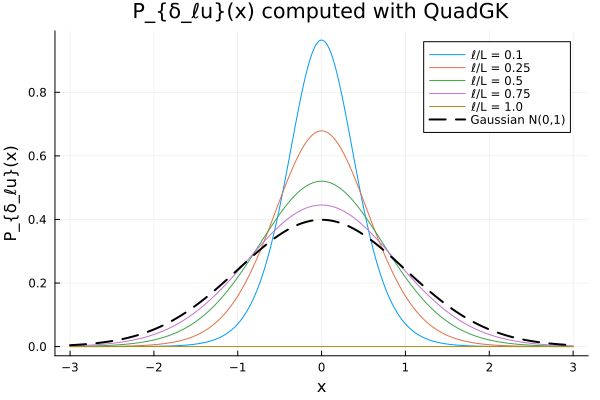

In [58]:
# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define x values
x_values = -3:0.01:3

# Create the plot for P_{δlu}(x)
p1 = plot(title = "P_{δ_ℓu}(x) computed with QuadGK",
          xlabel = "x",
          ylabel = "P_{δ_ℓu}(x)",
          lw = 2)

# Loop over each l and plot the corresponding density
for l in l_values
    P_values = [compute_P_δlu_of_x(l, x) for x in x_values]
    plot!(p1, x_values, P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
plot!(p1, x_values, P_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


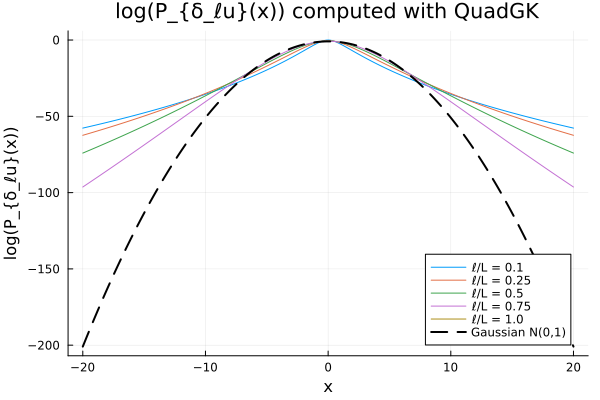

In [59]:
# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define x values
x_values = -20:0.01:20

# Create the plot for log(P_{δlu}(x))
p1 = plot(title = "log(P_{δ_ℓu}(x)) computed with QuadGK",
          xlabel = "x",
          ylabel = "log(P_{δ_ℓu}(x))",
          lw = 2)

# Loop over each l and plot log(P_{δlu}(x))
for l in l_values
    P_values = [compute_P_δlu_of_x(l, x) for x in x_values]
    log_P_values = [log(P) for P in P_values if P > 0]  # avoid log(0)
    valid_x = [x for (x, P) in zip(x_values, P_values) if P > 0]
    plot!(p1, valid_x, log_P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
logP_gauss = log.(P_gauss)
plot!(p1, x_values, logP_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


##### b. Entropy

In [60]:
function safe_integrand_entropy(l,x)
    p = compute_P_δlu_of_x(l, x)
    val = -p * log(p)
    return isfinite(val) ? val : 0.0
end

function compute_entropy_for_l(l)
    entropy, err = quadgk(
        x -> safe_integrand_entropy(l,x),
        -Inf, Inf;
    )
    return entropy
end

compute_entropy_for_l (generic function with 1 method)

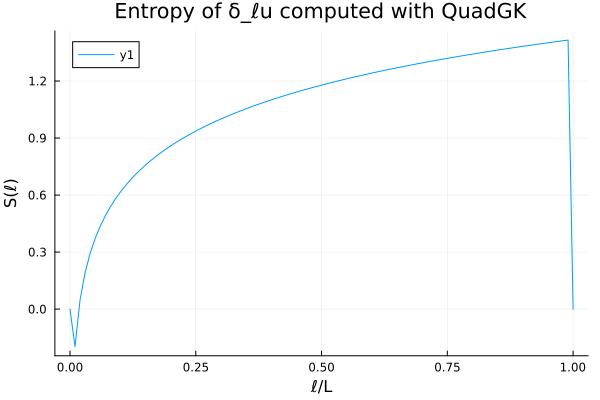

In [61]:
# Define l values
l_values = 0.0:0.01*L:L

# Create the plot for S(l)
p1 = plot(title = "Entropy of δ_ℓu computed with QuadGK",
          xlabel = "ℓ/L",
          ylabel = "S(ℓ)",
          lw = 2)

# Loop over each l and compute the entropies
S_values = [compute_entropy_for_l(l) for l in l_values]

# Plot
plot!(p1, l_values/L, S_values)
display(p1)


### 2. Non-normalized PDF, h*=c_1 (Laplace approximation)

##### a. P_{δ_ℓu}(x) and log(P_{δ_ℓu}(x))

In [19]:
# Value of h_star
h_star(l, x) = c1

h_star (generic function with 1 method)

In [20]:
function compute_P_δlu_of_x_Laplace(l, x; tol=1e-10, maxiter=100)
    # Asserts the validity of the Laplace point (f'' must be < 0)
    if fsecond(h_star(l, x), l, x) <= 0 || isnan(fsecond(h_star(l, x), l, x))
        return 0.0
    end

    prefactor = (1 / (sqrt(2π) * σ)) * sqrt((-log(l/L)) / c2) * sqrt(1 / (fsecond(h_star(l, x), l, x)))
    exponent = -f(h_star(l, x), l, x)

    exponent = clamp(exponent, -700, 700)
    return prefactor * exp(exponent)
end

compute_P_δlu_of_x_Laplace (generic function with 1 method)

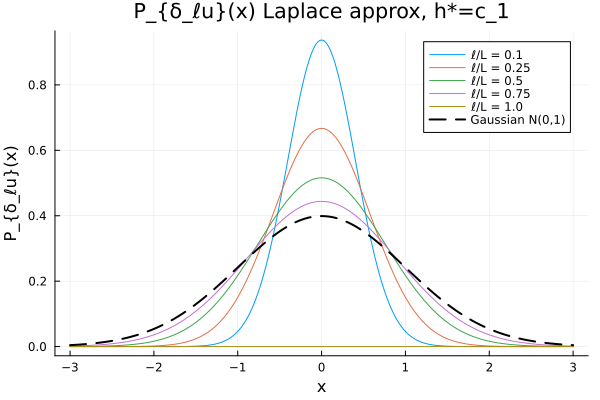

In [21]:
# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define x values
x_values = -3:0.01:3

# Create the plot for P_{δlu}(x)
p1 = plot(title = "P_{δ_ℓu}(x) Laplace approx, h*=c_1",
          xlabel = "x",
          ylabel = "P_{δ_ℓu}(x)",
          lw = 2)

# Loop over each l and plot the corresponding density
for l in l_values
    P_values = [compute_P_δlu_of_x_Laplace(l, x) for x in x_values]
    plot!(p1, x_values, P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
plot!(p1, x_values, P_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


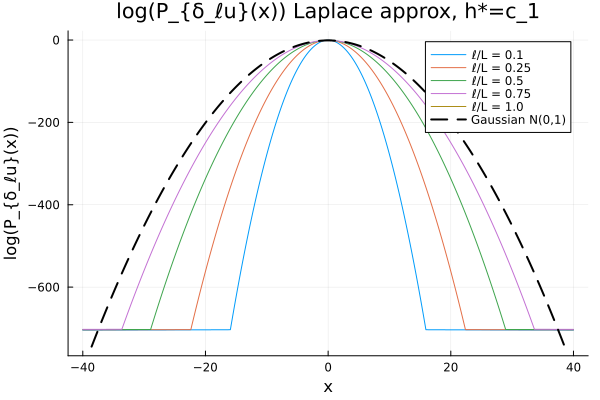

In [22]:
# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define x values
x_values = -40:0.01:40

# Create the plot for log(P_{δlu}(x))
p1 = plot(title = "log(P_{δ_ℓu}(x)) Laplace approx, h*=c_1",
          xlabel = "x",
          ylabel = "log(P_{δ_ℓu}(x))",
          lw = 2)

# Loop over each l and plot log(P_{δlu}(x))
for l in l_values
    P_values = [compute_P_δlu_of_x_Laplace(l, x) for x in x_values]
    log_P_values = [log(P) for P in P_values if P > 0]  # avoid log(0)
    valid_x = [x for (x, P) in zip(x_values, P_values) if P > 0]
    plot!(p1, valid_x, log_P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
logP_gauss = log.(P_gauss)
plot!(p1, x_values, logP_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


##### b. Entropy

In [23]:
Entropy = Float64[]

# x-grid (must be sufficiently large)
x_min = -20.0
x_max = 20.0
dx = 0.01
x_vals = x_min:dx:x_max

l_values = [0.10*L, 0.25*L, 0.5*L, 0.75*L]

for l in l_values

    # 1) Compute PDF values from your function
    P_vals = [compute_P_δlu_of_x_Laplace(l, x) for x in x_vals]

    # println("l/L = 1 → ∫P dx = ", sum(P_vals)*dx)

    # 2) Numerical normalization
    norm = sum(P_vals) * dx
    P_vals .= P_vals ./ norm

    # 3) Shannon entropy: S(l) = -∫ P log P dx
    S_l = -sum(
        P * log(P) * dx
        for P in P_vals if P > 0
        init = 0.0
    )

    push!(Entropy, S_l)
end

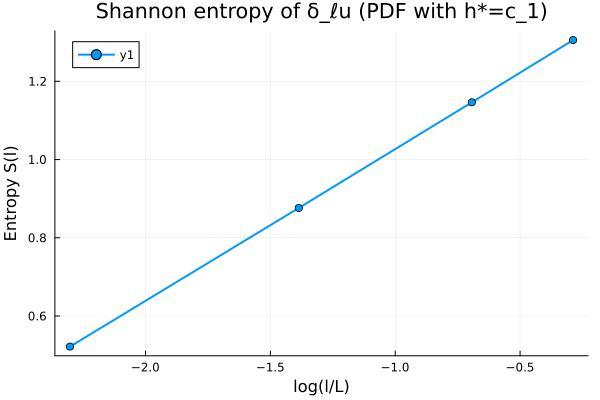

In [24]:
pS = plot(
    log.(l_values ./ L),
    Entropy,
    marker=:circle,
    lw=2,
    xlabel="log(l/L)",
    ylabel="Entropy S(l)",
    title="Shannon entropy of δ_ℓu (PDF with h*=c_1)"
)
display(pS)

### 3. Non-normalized PDF, h* computed with Lambert W function (Laplace approximation)

##### a. P_{δ_ℓu}(x) and log(P_{δ_ℓu}(x))

In [25]:
# Value of h_star
using LambertW
h_star(l, x) = (c1 + c2) - lambertw(2 * c2 * abs(log(l / L)) * ((x / σ)^2) * exp(2 * (c1 + c2) * abs(log(l / L)))) / (2 * abs(log(l / L)))

h_star (generic function with 1 method)

In [26]:
function compute_P_δlu_of_x_Laplace(l, x; tol=1e-10, maxiter=100)
    # Asserts the validity of the Laplace point (f'' must be < 0)
    if fsecond(h_star(l, x), l, x) <= 0 || isnan(fsecond(h_star(l, x), l, x))
        return 0.0
    end

    prefactor = (1 / (sqrt(2π) * σ)) * sqrt((-log(l/L)) / c2) * sqrt(1 / (fsecond(h_star(l, x), l, x)))
    exponent = -f(h_star(l, x), l, x)

    exponent = clamp(exponent, -700, 700)
    return prefactor * exp(exponent)
end

compute_P_δlu_of_x_Laplace (generic function with 1 method)

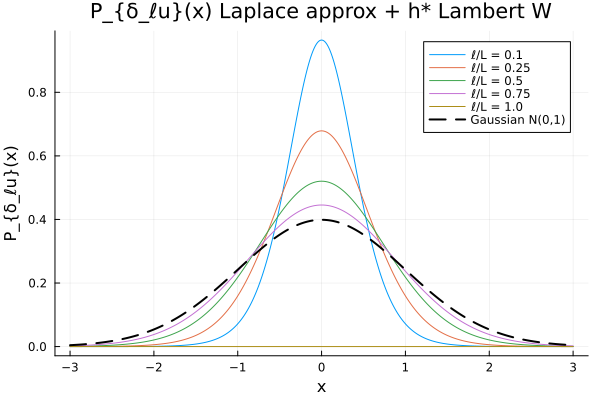

In [27]:
# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define x values
x_values = -3:0.01:3

# Create the plot for P_{δlu}(x)
p1 = plot(title = "P_{δ_ℓu}(x) Laplace approx + h* Lambert W",
          xlabel = "x",
          ylabel = "P_{δ_ℓu}(x)",
          lw = 2)

# Loop over each l and plot the corresponding density
for l in l_values
    P_values = [compute_P_δlu_of_x_Laplace(l, x) for x in x_values]
    plot!(p1, x_values, P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
plot!(p1, x_values, P_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


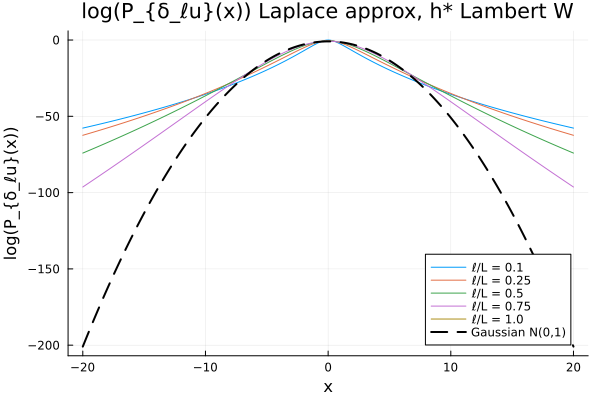

In [28]:
# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define x values
x_values = -20:0.01:20

# Create the plot for log(P_{δlu}(x))
p1 = plot(title = "log(P_{δ_ℓu}(x)) Laplace approx, h* Lambert W",
          xlabel = "x",
          ylabel = "log(P_{δ_ℓu}(x))",
          lw = 2)

# Loop over each l and plot log(P_{δlu}(x))
for l in l_values
    P_values = [compute_P_δlu_of_x_Laplace(l, x) for x in x_values]
    log_P_values = [log(P) for P in P_values if P > 0]  # avoid log(0)
    valid_x = [x for (x, P) in zip(x_values, P_values) if P > 0]
    plot!(p1, valid_x, log_P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
P_gauss = pdf.(gauss, x_values)
logP_gauss = log.(P_gauss)
plot!(p1, x_values, logP_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


##### b. Entropy

In [29]:
Entropy = Float64[]

# x-grid (must be sufficiently large)
x_min = -20.0
x_max = 20.0
dx = 0.01
x_vals = x_min:dx:x_max

l_values = [0.10*L, 0.25*L, 0.5*L, 0.75*L]

for l in l_values

    # 1) Compute PDF values from your function
    P_vals = [compute_P_δlu_of_x_Laplace(l, x) for x in x_vals]

    # println("l/L = 1 → ∫P dx = ", sum(P_vals)*dx)

    # 2) Numerical normalization
    norm = sum(P_vals) * dx
    P_vals .= P_vals ./ norm

    # 3) Shannon entropy: S(l) = -∫ P log P dx
    S_l = -sum(
        P * log(P) * dx
        for P in P_vals if P > 0
        init = 0.0
    )

    push!(Entropy, S_l)
end

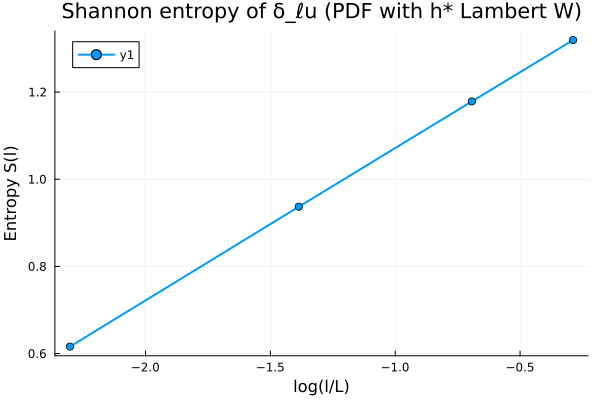

In [30]:
pS = plot(
    log.(l_values ./ L),
    Entropy,
    marker=:circle,
    lw=2,
    xlabel="log(l/L)",
    ylabel="Entropy S(l)",
    title="Shannon entropy of δ_ℓu (PDF with h* Lambert W)"
)
display(pS)

### 4. Second order structure function and flatness

In [16]:
# PDF model:
pdf_fun = compute_P_δlu_of_x             # exact QuadGK version
# pdf_fun = compute_P_δlu_of_x_Laplace   # Laplace version (uncomment if needed)

# x-range 
x_min = -20
x_max = 20
x_step = 0.01
x_vals = x_min:x_step:x_max

# Allocate containers
S1 = Float64[]
S2 = Float64[]
S3 = Float64[]
S4 = Float64[]
Flatness = Float64[]

dx = x_vals[2] - x_vals[1]

for l in l_values

    P_vals = [pdf_fun(l, x) for x in x_vals]

    # Normalisation OBLIGATOIRE
    norm = sum(P_vals) * dx
    P_vals .= P_vals ./ norm     # <--- la seule correction indispensable

    # Moments
    S1_l = sum( x * P * dx for (x,P) in zip(x_vals, P_vals) )
    S2_l = sum( x^2 * P * dx for (x,P) in zip(x_vals, P_vals) ) - S1_l^2
    S3_l = sum( x^3 * P * dx for (x,P) in zip(x_vals, P_vals) )
    S4_l = sum( x^4 * P * dx for (x,P) in zip(x_vals, P_vals) )

    push!(S1, S1_l)
    push!(S2, S2_l)
    push!(S3, S3_l)
    push!(S4, S4_l)
    push!(Flatness, S4_l / S2_l^2)
end

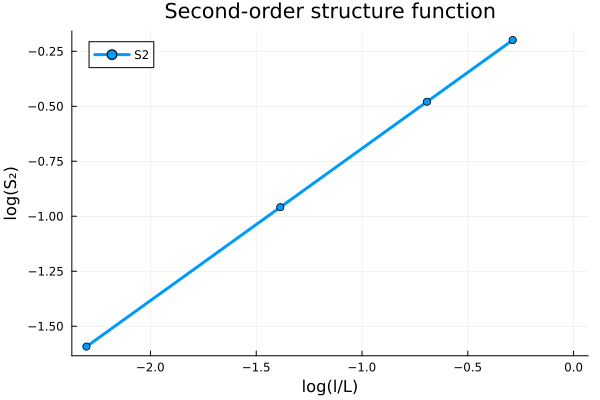

In [17]:
# S2 vs l
pS2 = plot(
    log.(l_values ./ L),
    log.(S2),
    xlabel = "log(l/L)",
    ylabel = "log(S₂)",
    lw = 3, marker = :circle,
    label="S2",
    title = "Second-order structure function"
)

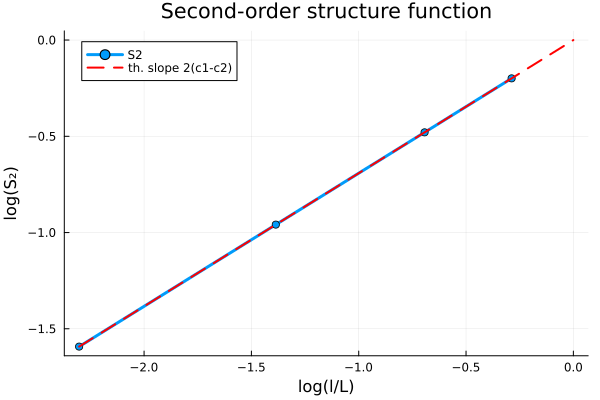

In [18]:
# theoretical slope 2(c1 - c2)
plot!(pS2,
      log.(l_values./L),
      log.(l_values./L) .* (2*(c1 - c2)),
      lw=2, ls=:dash, color=:red, label="th. slope 2(c1-c2)")

display(pS2)

In [19]:
# Skewness S3/S2^(3/2)
#pS3 = plot(
#    log.(l_values ./ L),
#    S3 ./ (S2 .^ (3/2)),
#    xlabel="log(l/L)",
#    ylabel="S₃ / S₂^{3/2}",
#    marker=:circle,
#    title="Skewness"
#)
#plot!(pS3, log.(l_values ./ L), zeros(length(l_values)), color=:red, lw=2, ls=:dash)

#display(pS3)

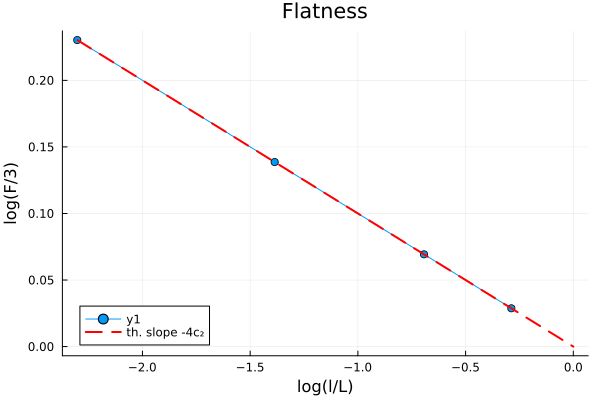

In [20]:
# Flatness F = S4/S2^2
pF = plot(
    log.(l_values ./ L),
    log.(Flatness ./ 3),
    xlabel="log(l/L)",
    ylabel="log(F/3)",
    marker=:circle,
    title="Flatness"
)

plot!(pF,
      log.(l_values./L),
      (-4*c2) .* log.(l_values./L),
      color=:red, lw=2, ls=:dash, label="th. slope -4c₂")

display(pF)